      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL             No  ...   
1        

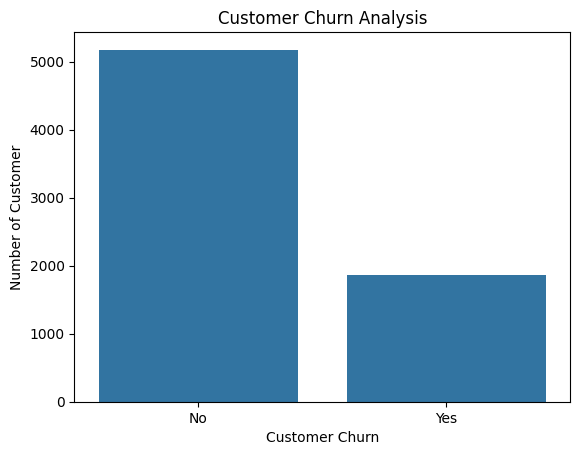

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("customer_churn_analysis.csv")
print(df)

print(df.info())
print(df.head(10))
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.value_counts().head())
print((df["TotalCharges"].str.strip()=="").sum())
df["TotalCharges"]=df["TotalCharges"].str.strip()
df["TotalCharges"]=df["TotalCharges"].replace("",np.nan)
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"])
print(df["TotalCharges"].isnull().sum())
df["TotalCharges"]=df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df.dtypes)
print(df["TotalCharges"].isnull().sum())
print("Final Dataset Shape:",df.shape)
print("Total Customers:",df["customerID"].count())
print("Total Churn:",(df["Churn"]=="Yes").sum())
print("Total Churn:",(df["Churn"]=="No").sum())
Churn_rate=(df["Churn"]=="Yes").mean() *100
print("Churn_rate:", round(Churn_rate,2),"%")
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Analysis")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customer")
plt.savefig("customer_churn.png", dpi=380, bbox_inches="tight")
plt.show()


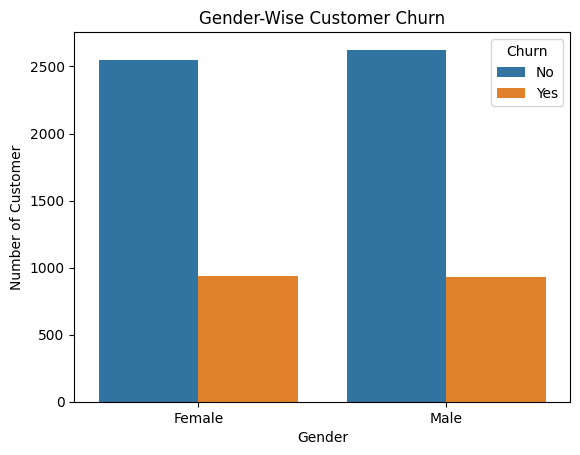

In [5]:
sns.countplot(data=df,x="gender", hue="Churn")
plt.title("Gender-Wise Customer Churn")
plt.xlabel("Gender")
plt.ylabel("Number of Customer")
plt.savefig("gender_wise_churn.png", dpi=300, bbox_inches="tight")
plt.show()

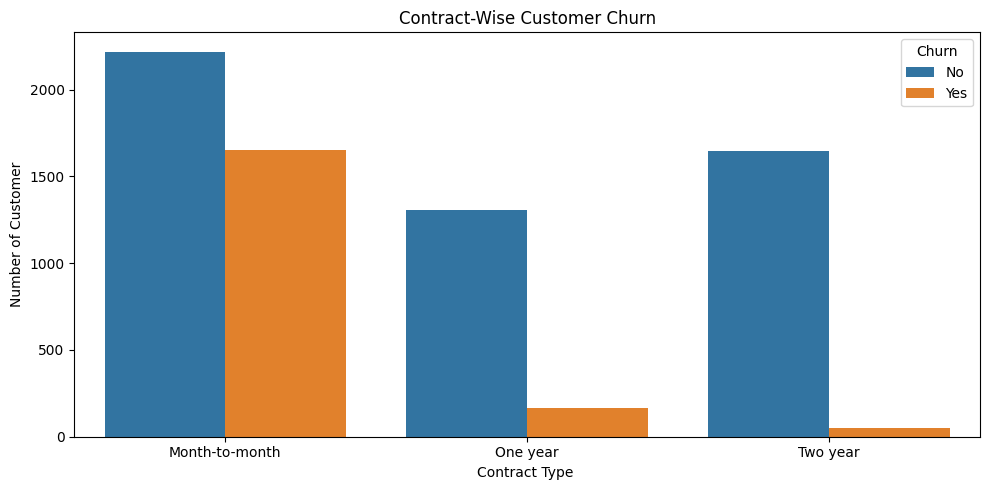

In [7]:
plt.figure (figsize=(10,5))
sns.countplot(data=df,x="Contract",hue="Churn")
plt.title("Contract-Wise Customer Churn")
plt.xlabel("Contract Type ")
plt.ylabel("Number of Customer")
plt.tight_layout()
plt.savefig("Contract-wise_churn.png", dpi=300, bbox_inches="tight")
plt.show()

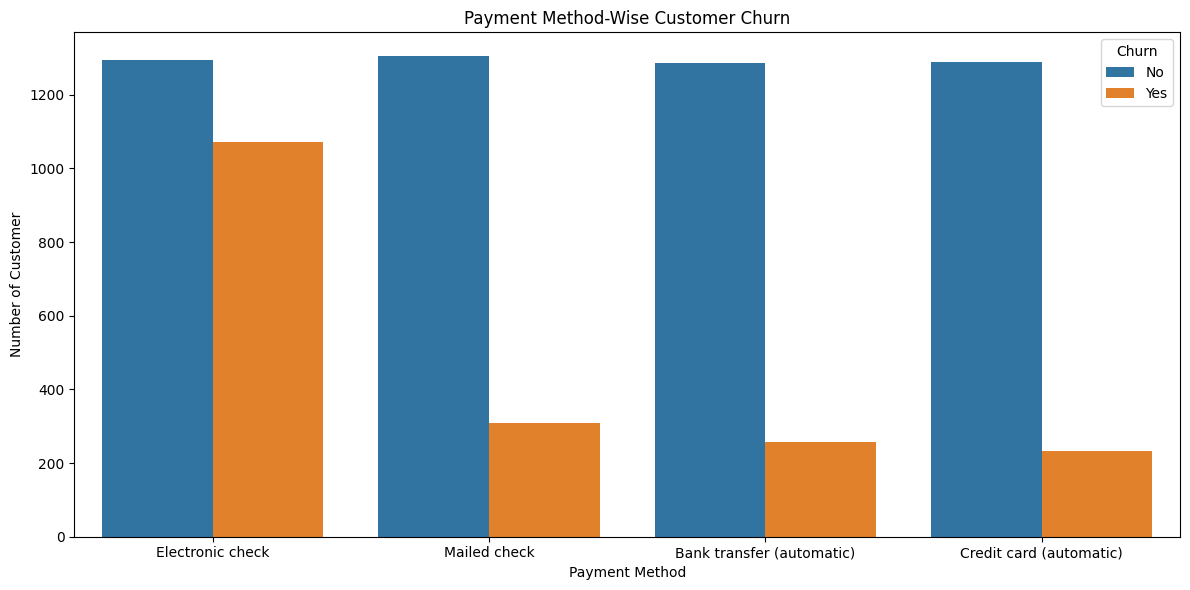

In [12]:
plt.figure(figsize=(12,6))
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Payment Method-Wise Customer Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customer")
#plt.xticks(rotation=20)
plt.savefig("Payment method-wise Churn.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

              

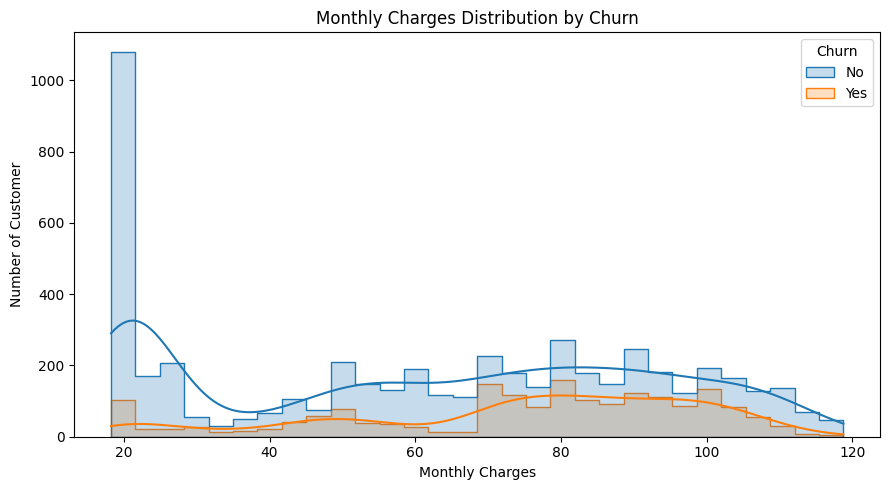

In [17]:
plt.figure(figsize=(9,5))
sns.histplot(data=df,x="MonthlyCharges",hue="Churn",bins=30,kde=True,element="step")
plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customer")
plt.tight_layout()
plt.savefig("Monthly_wise_churn.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
monthly_avg=df.groupby("Churn")["MonthlyCharges"].mean()
print(monthly_avg.round(2))

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [20]:
tenure_avg=df.groupby("Churn")["tenure"].mean()
print(tenure_avg.round(2))

Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


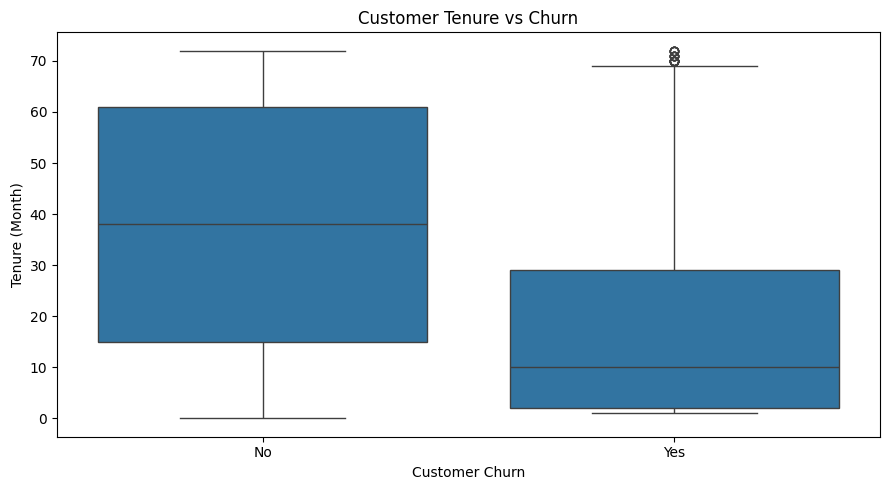

In [22]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df,x="Churn",y="tenure")
plt.title("Customer Tenure vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Month)")
plt.tight_layout()
plt.savefig("Customer tenure vs churn.png", dpi=300, bbox_inches="tight")
plt.show()


In [7]:
df["TenureGroup"]= pd.cut(
    df["tenure"],
    bins=[-1,12,24,48,72],
labels=["0-12 Months","13-24 Months","25-48 Months","49-72 Months"])

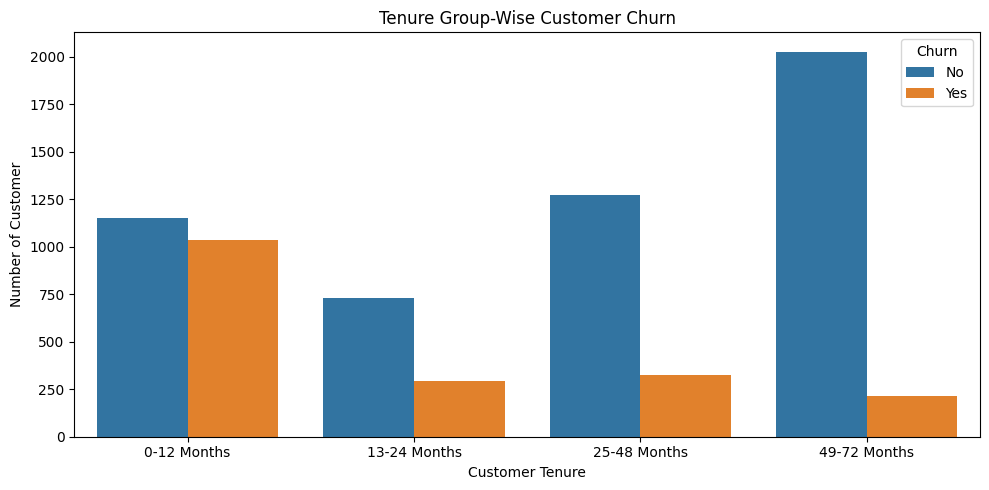

In [9]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="TenureGroup",hue="Churn"),
plt.title("Tenure Group-Wise Customer Churn")
plt.xlabel("Customer Tenure")
plt.ylabel("Number of Customer")
plt.tight_layout()
plt.savefig("Tenure Group churn.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
payment_churn=pd.crosstab(df["PaymentMethod"],df["Churn"],normalize="index")*100
print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


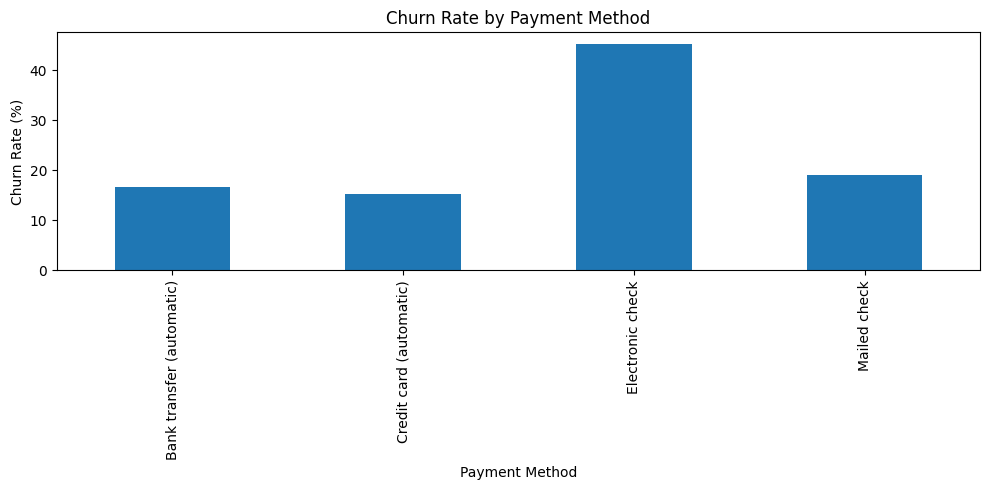

In [14]:
plt.figure(figsize=(10,5))
payment_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig("payment churn rate.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
df["CustomerType"]=df["SeniorCitizen"].map({0: "Non-SeniorCitizen",
                                            1: "SeniorCitizen"})
print(df["CustomerType"].value_counts())


CustomerType
Non-SeniorCitizen    5901
SeniorCitizen        1142
Name: count, dtype: int64


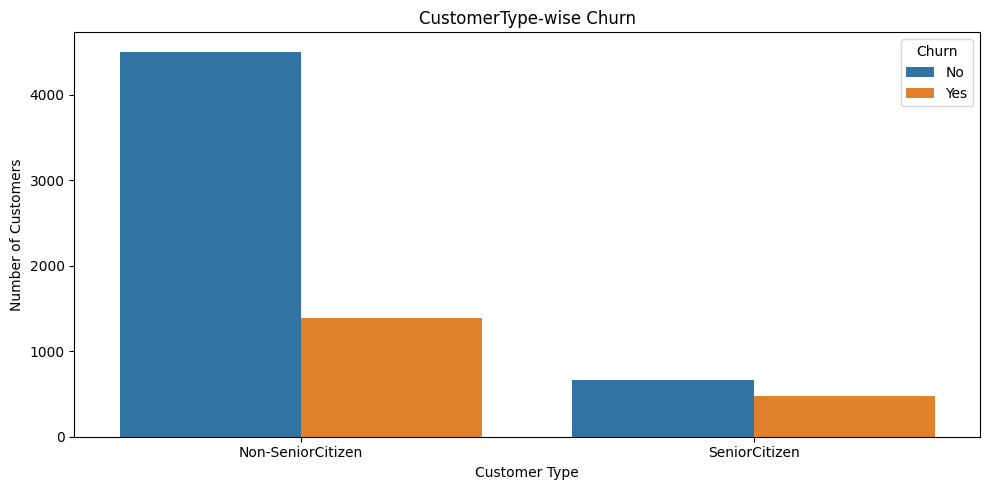

In [25]:
plt.figure(figsize=(10,5))
sns.countplot(data=df,x="CustomerType",hue="Churn"),
plt.title("CustomerType-wise Churn")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("CustomerType.png", dpi=300, bbox_inches="tight")
plt.show()

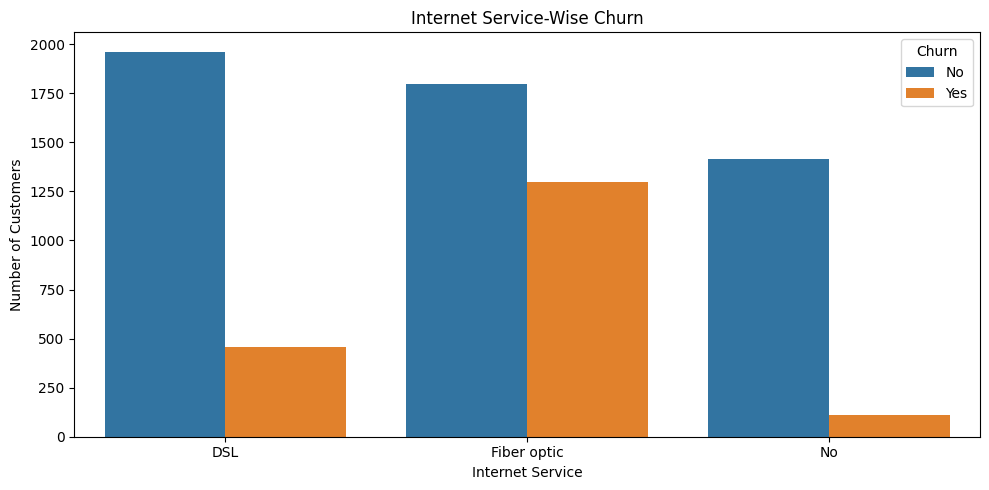

In [26]:
plt.figure(figsize=(10,5))
sns.countplot(data=df,x="InternetService",hue="Churn")
plt.title("Internet Service-Wise Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("Internet service wise churn.png", dpi=300, bbox_inches="tight")
plt.show()

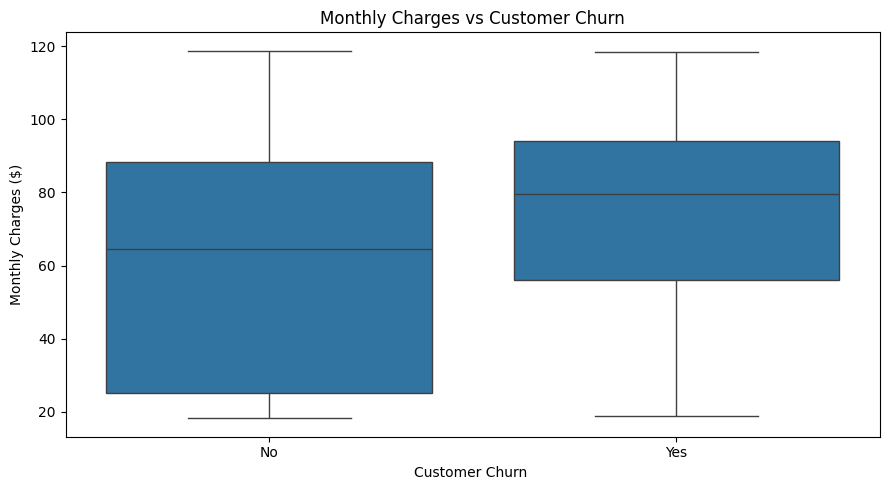

In [39]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df,x="Churn",y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn ")
plt.ylabel("Monthly Charges ($)")
plt.tight_layout()
plt.savefig("Monthly charges vs Customer Churn.png", dpi=300, bbox_inches="tight")
plt.show()

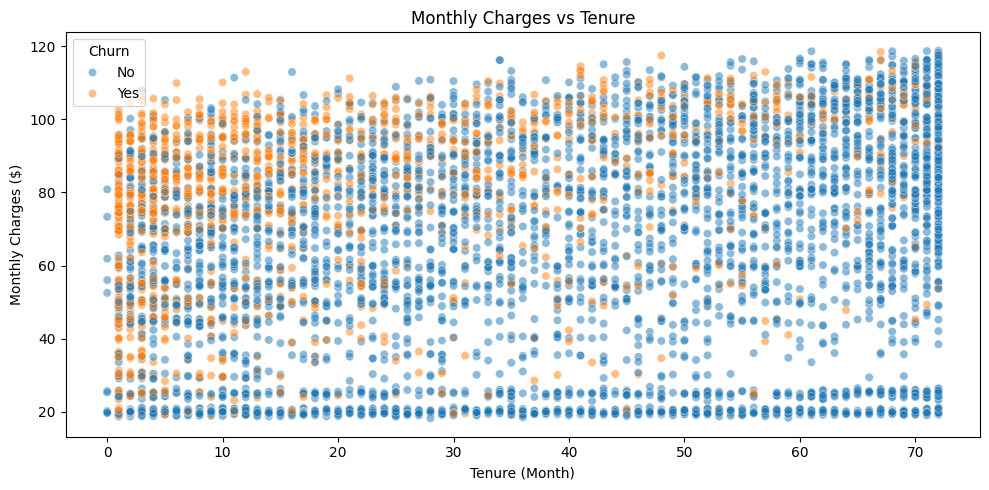

In [40]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df,x="tenure",y="MonthlyCharges",hue="Churn",alpha=0.5)
plt.title("Monthly Charges vs Tenure")
plt.xlabel("Tenure (Month)")
plt.ylabel("Monthly Charges ($)")
plt.tight_layout()
plt.savefig("Monthly Charges vs Tenure.png", dpi=300, bbox_inches="tight")
plt.show()

In [46]:
print(df[["TotalCharges","tenure","MonthlyCharges"]].dtypes)

TotalCharges       object
tenure              int64
MonthlyCharges    float64
dtype: object


In [48]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce") 
df["TotalCharges"]=df["TotalCharges"].fillna(0)

In [49]:
correlation =df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()
print(correlation.round(2))

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


In [50]:
print(df[["TotalCharges","MonthlyCharges","tenure"]].dtypes)

TotalCharges      float64
MonthlyCharges    float64
tenure              int64
dtype: object


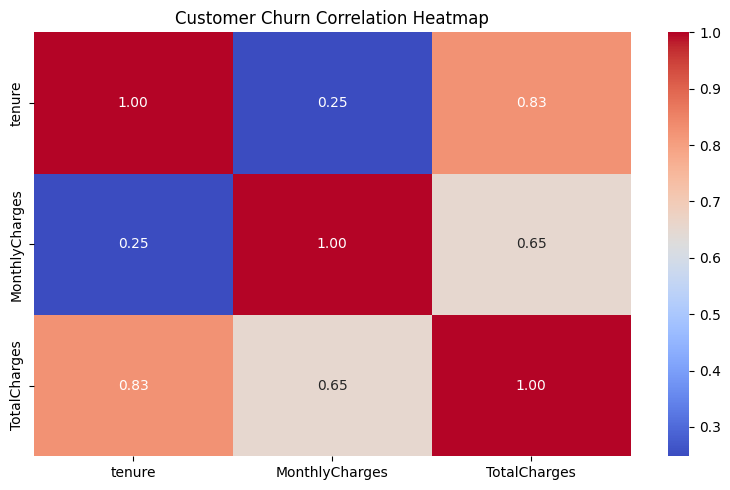

In [52]:
correlation =df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()
plt.figure(figsize=(8,5))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Customer Churn Correlation Heatmap")
plt.tight_layout()
plt.savefig("Customer Churn Correlation.png", dpi=300, bbox_inches="tight")
plt.show()